In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('results')
GRAPHS_DIR = Path('graphs')
GRAPHS_DIR.mkdir(exist_ok=True)

In [16]:
df = pd.read_csv(RESULTS_DIR / 'ejercicio3_primos.csv')
df['pct_sync'] = (df['t_sync_s'] / df['t_total_s']) * 100.0
df

,particion,proceso,t_calculo_s,t_sync_s,t_total_s,primos_locales,primos_totales,pct_sync
0,1000,0,0.657254,0.109448,0.766702,133119,664579,14.275168
1,1000,1,0.658082,0.108608,0.766690,132993,664579,14.165830
2,1000,2,0.685858,0.080833,0.766691,132667,664579,10.543100
3,1000,3,0.766480,0.000077,0.766558,133045,664579,0.010045
4,1000,4,0.723266,0.043274,0.766540,132755,664579,5.645367
5,10000,0,0.662409,0.071105,0.733513,133317,664579,9.693761
6,10000,1,0.618615,0.114857,0.733473,132866,664579,15.659336
7,10000,2,0.619241,0.114231,0.733473,132983,664579,15.573988
8,10000,3,0.731829,0.001546,0.733375,132639,664579,0.210806
9,10000,4,0.733348,0.000021,0.733370,132774,664579,0.002863


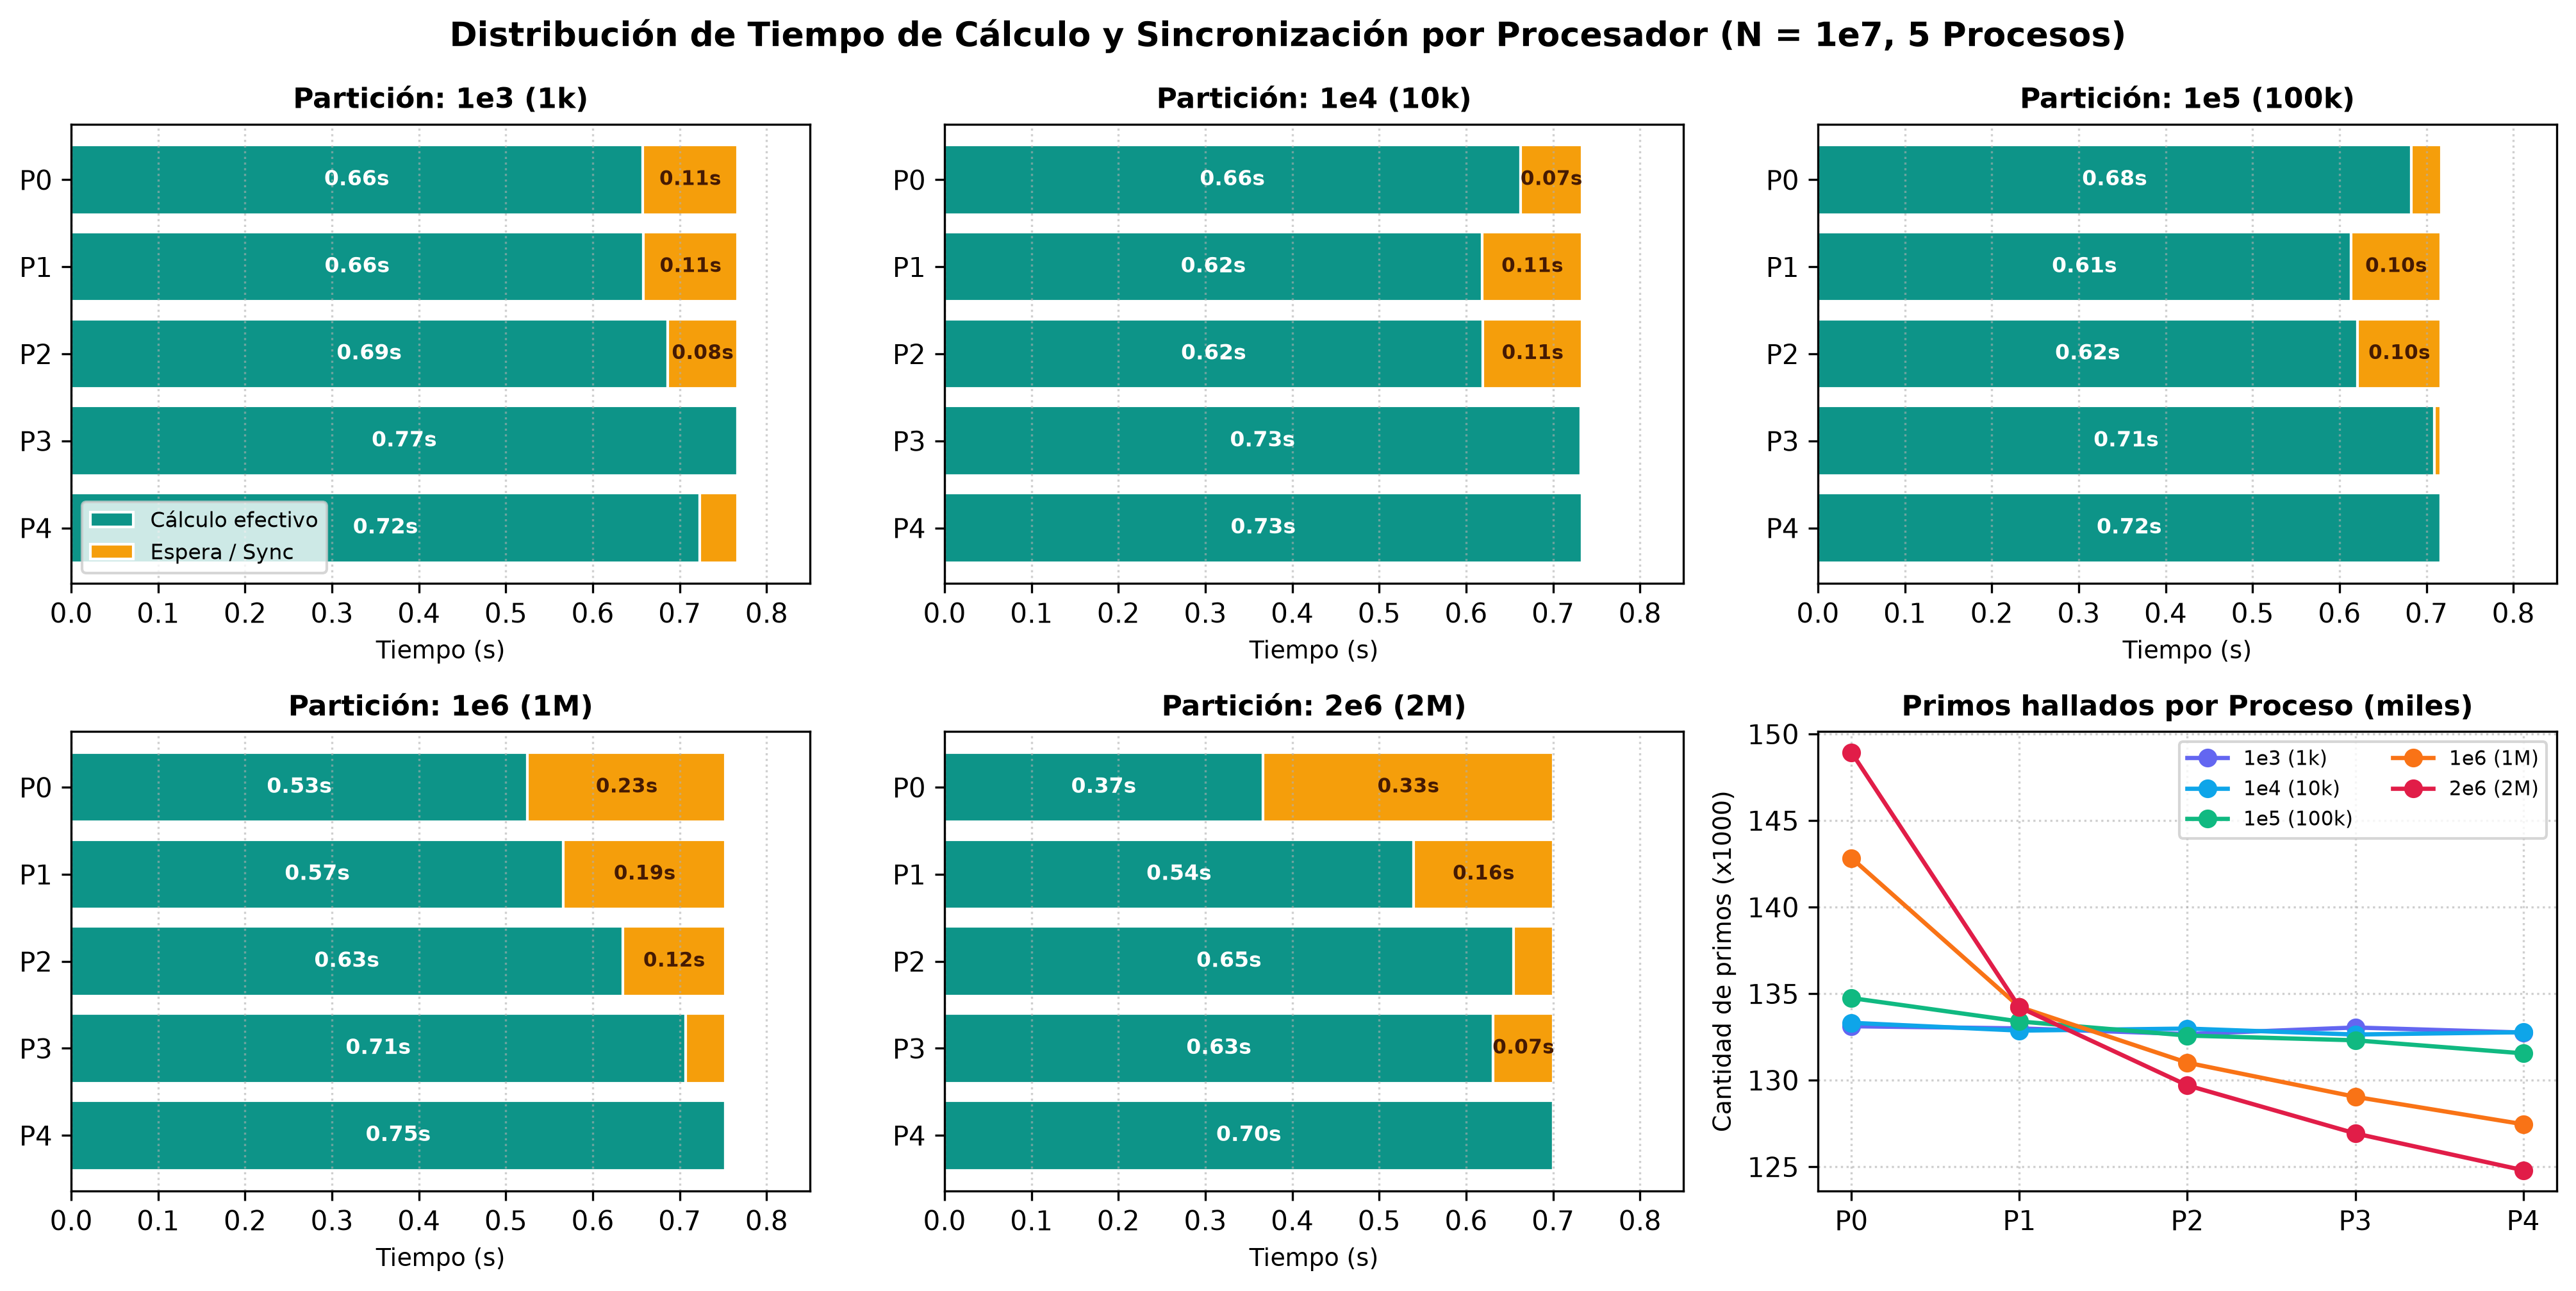

In [17]:
particiones_val = [1000, 10000, 100000, 1000000, 2000000]
etiquetas_part = ['1e3 (1k)', '1e4 (10k)', '1e5 (100k)', '1e6 (1M)', '2e6 (2M)']
procesos = ['P0', 'P1', 'P2', 'P3', 'P4']

fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.8), dpi=300)
axes_flat = axes.flatten()

for idx, (p_val, p_lbl) in enumerate(zip(particiones_val, etiquetas_part)):
    sub = df[df['particion'] == p_val].sort_values('proceso')
    t_calc = sub['t_calculo_s'].to_numpy()
    t_sync = sub['t_sync_s'].to_numpy()

    ax = axes_flat[idx]
    ax.barh(procesos, t_calc, color='#0d9488', edgecolor='white', label='Cálculo efectivo')
    ax.barh(procesos, t_sync, left=t_calc, color='#f59e0b', edgecolor='white', label='Espera / Sync')

    for y_i, (c_val, s_val) in enumerate(zip(t_calc, t_sync)):
        ax.text(c_val / 2, y_i, f'{c_val:.2f}s', va='center', ha='center', color='white', fontsize=8, fontweight='bold')
        if s_val >= 0.06:
            ax.text(c_val + s_val / 2, y_i, f'{s_val:.2f}s', va='center', ha='center', color='#451a03', fontsize=7.5, fontweight='bold')

    ax.set_xlim(0, 0.85)
    ax.invert_yaxis()
    ax.set_title(f'Partición: {p_lbl}', fontsize=10.5, fontweight='bold')
    ax.set_xlabel('Tiempo (s)', fontsize=9)
    ax.grid(True, axis='x', linestyle=':', alpha=0.6)
    if idx == 0:
        ax.legend(loc='lower left', fontsize=8)

# Sexto panel: Comparación de primos encontrados por proceso en cada partición
ax6 = axes_flat[5]
colores_p = ['#6366f1', '#0ea5e9', '#10b981', '#f97316', '#e11d48']
for p_val, p_lbl, col in zip(particiones_val, etiquetas_part, colores_p):
    sub = df[df['particion'] == p_val].sort_values('proceso')
    ax6.plot(procesos, sub['primos_locales'] / 1000.0, marker='o', linewidth=1.6, color=col, label=p_lbl)

ax6.set_title('Primos hallados por Proceso (miles)', fontsize=10.5, fontweight='bold')
ax6.set_ylabel('Cantidad de primos (x1000)', fontsize=9)
ax6.grid(True, linestyle=':', alpha=0.6)
ax6.legend(fontsize=7.5, ncol=2)

fig.suptitle('Distribución de Tiempo de Cálculo y Sincronización por Procesador (N = 1e7, 5 Procesos)', fontsize=12.5, fontweight='bold')
plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e3_balance_carga_particiones.png', dpi=300)
plt.show()

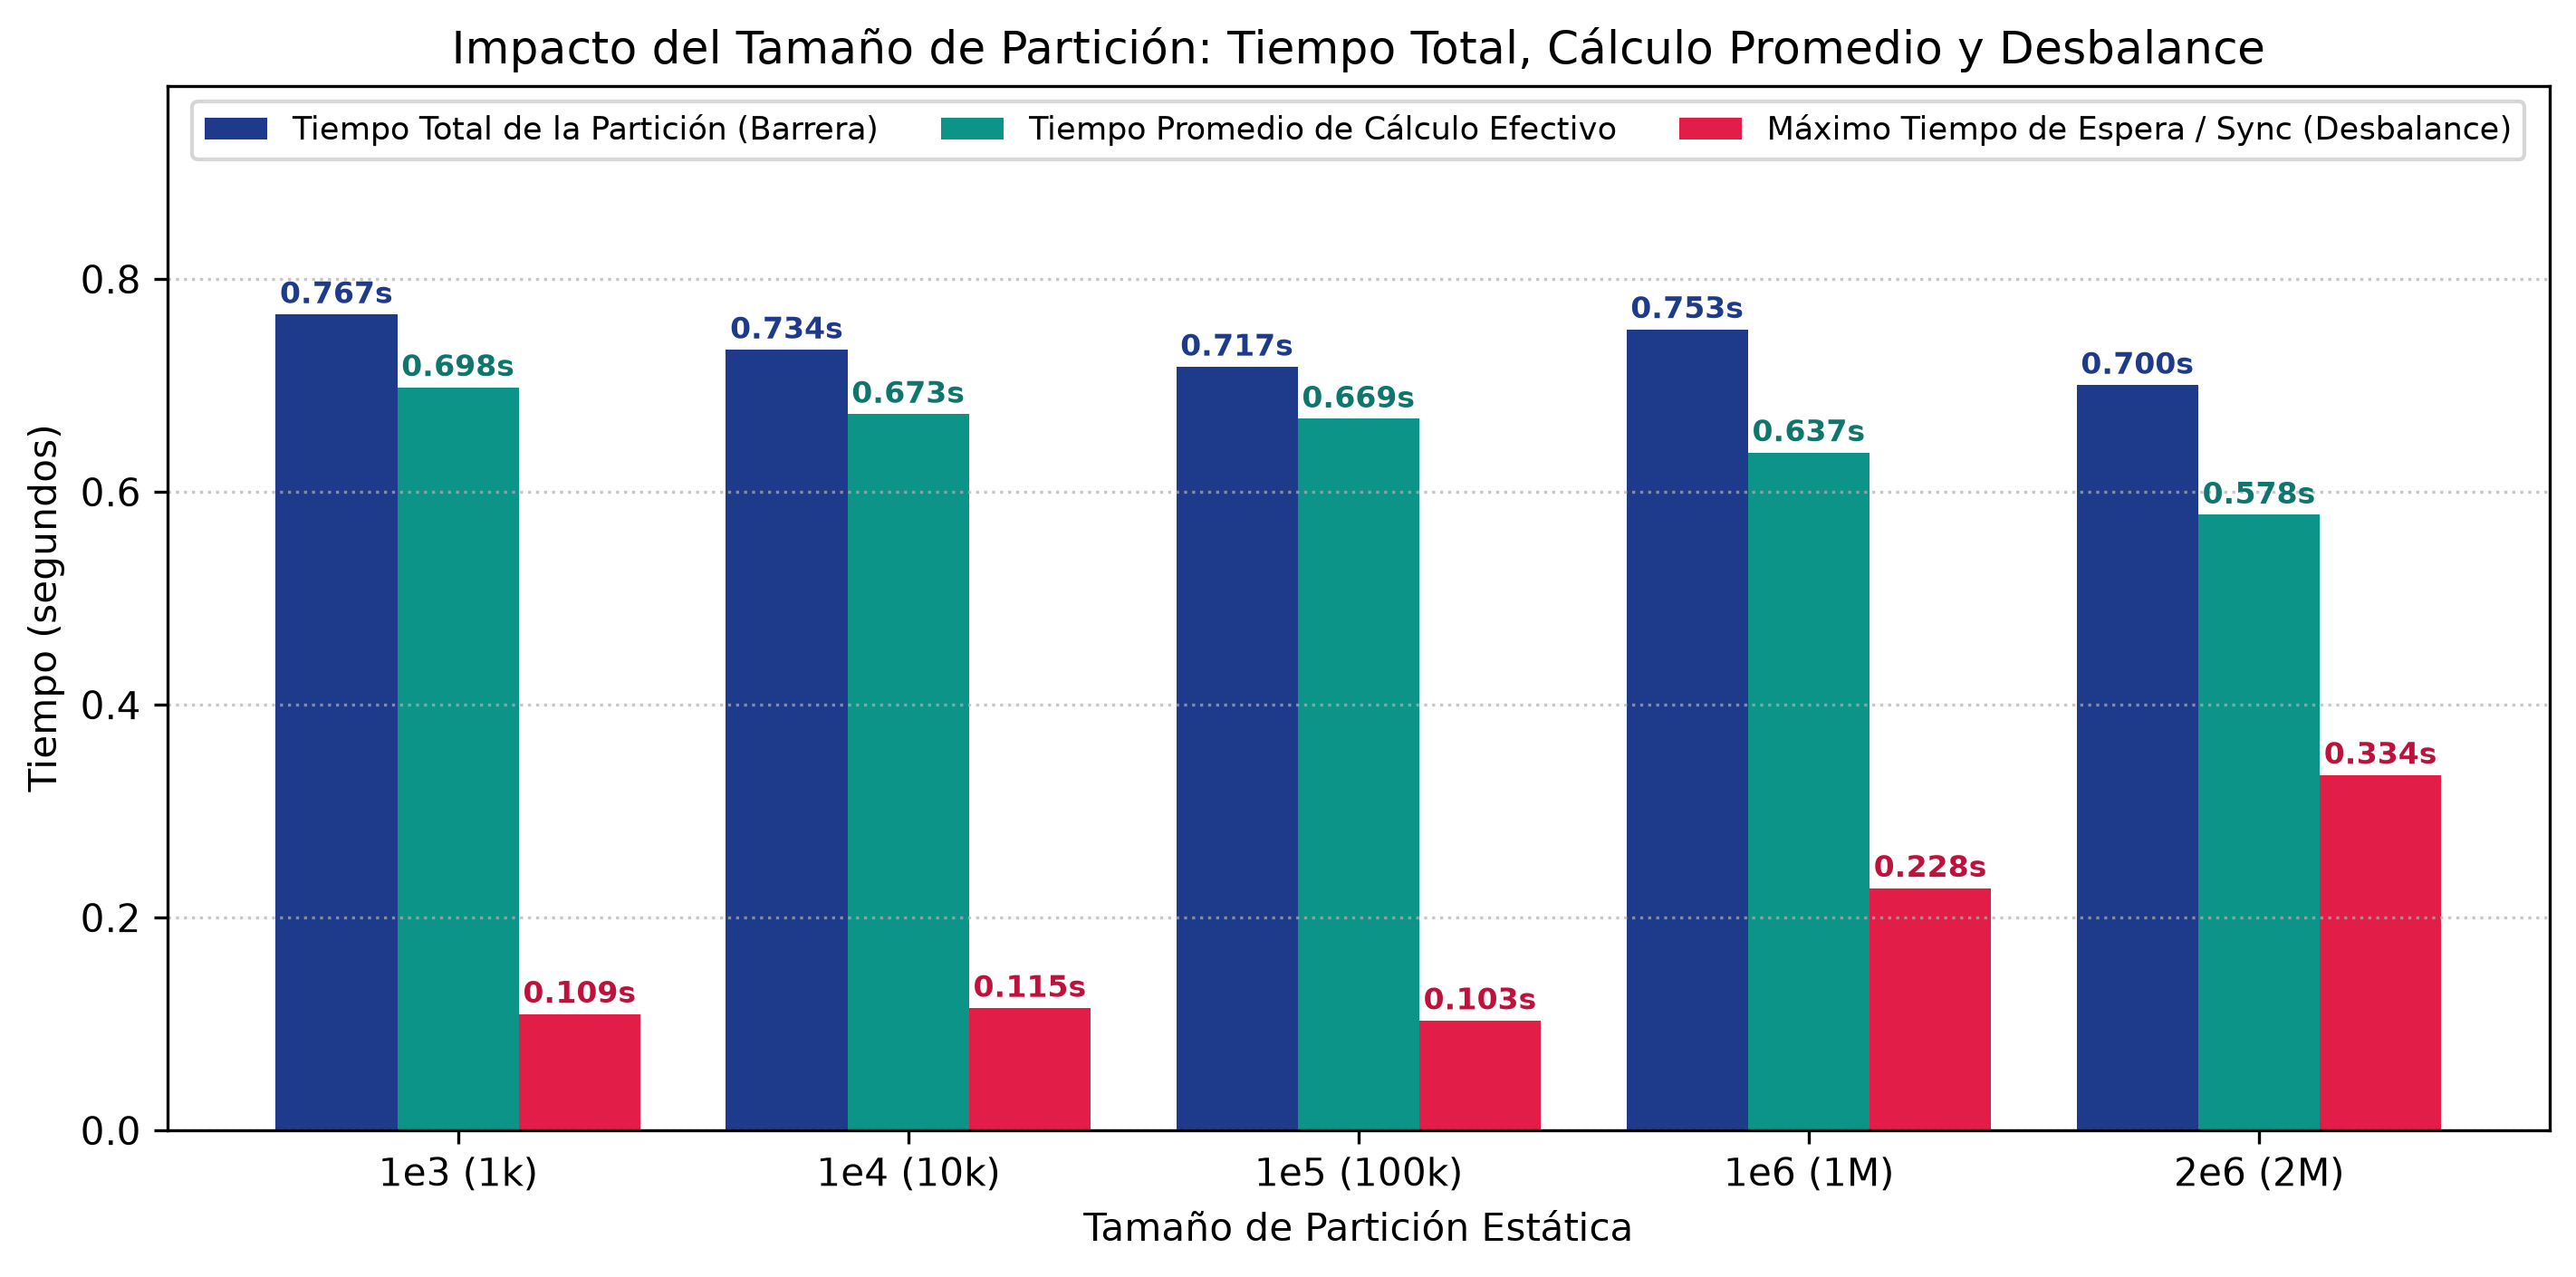

In [18]:
t_total_max = [df[df['particion'] == p]['t_total_s'].max() for p in particiones_val]
t_calc_prom = [df[df['particion'] == p]['t_calculo_s'].mean() for p in particiones_val]
t_sync_max = [df[df['particion'] == p]['t_sync_s'].max() for p in particiones_val]

x = np.arange(len(etiquetas_part))
ancho = 0.27

fig, ax = plt.subplots(figsize=(10, 4.8), dpi=300)

b_tot = ax.bar(x - ancho, t_total_max, width=ancho, color='#1e3a8a', label='Tiempo Total de la Partición (Barrera)')
b_prom = ax.bar(x, t_calc_prom, width=ancho, color='#0d9488', label='Tiempo Promedio de Cálculo Efectivo')
b_sync = ax.bar(x + ancho, t_sync_max, width=ancho, color='#e11d48', label='Máximo Tiempo de Espera / Sync (Desbalance)')

for bars, col in [(b_tot, '#1e3a8a'), (b_prom, '#0f766e'), (b_sync, '#be123c')]:
    for b in bars:
        h = b.get_height()
        ax.annotate(f'{h:.3f}s', (b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8, color=col, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(etiquetas_part)
ax.set_ylim(0, max(t_total_max) * 1.28)
ax.set_xlabel('Tamaño de Partición Estática')
ax.set_ylabel('Tiempo (segundos)')
ax.set_title('Impacto del Tamaño de Partición: Tiempo Total, Cálculo Promedio y Desbalance')
ax.legend(loc='upper center', ncol=3, fontsize=8.3)
ax.grid(True, axis='y', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e3_tiempo_total_particion.png', dpi=300)
plt.show()